In [2]:
import numpy as np
import matplotlib.pyplot as plt

fs = 200
duration = 5
N = fs * duration
t = np.arange(N) / fs

# Useful robot angular velocity
clean = (np.sin(2*np.pi*1*t) + 0.4*np.sin(2*np.pi*3*t))

# Reference correlated with motor interference
x_ref = np.sin(2*np.pi*65*t)

# Primary measurement: clean signal + interference
d = clean + 0.6*x_ref

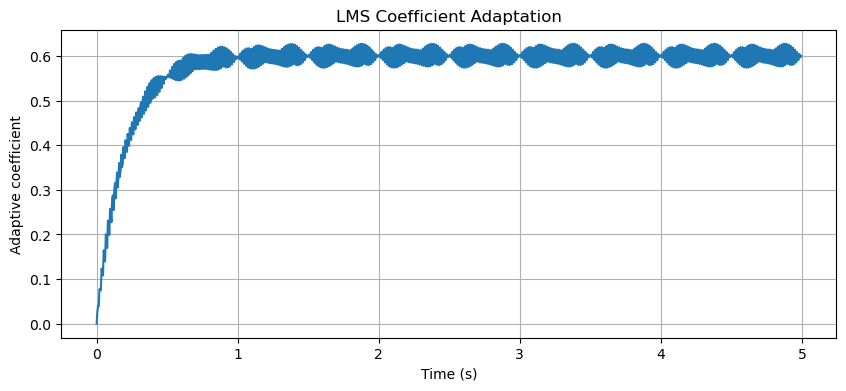

In [18]:
mu = 0.05
w = 0.0
y = np.zeros(N)
e = np.zeros(N)
w_history = np.zeros(N)
for n in range(N):
    y[n] = w * x_ref[n]
    e[n] = d[n] - y[n]
    w = w + mu * e[n] * x_ref[n]
    w_history[n] = w

plt.figure(figsize=(10, 4))
plt.plot(t, w_history)

plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("LMS Coefficient Adaptation")
plt.grid(True)
plt.show()

Filter has learned the interference coefficient automatically (without setting it to 0.6) at in about 0.7 seconds

Furthermore, the coefficient keeps osscillating around 0.6 instead of becoming constant. This is because d contains useful signals as well, So error(e) does not become zero.

What I should consider next is that whether LMS output (e) resembles the original clean signal

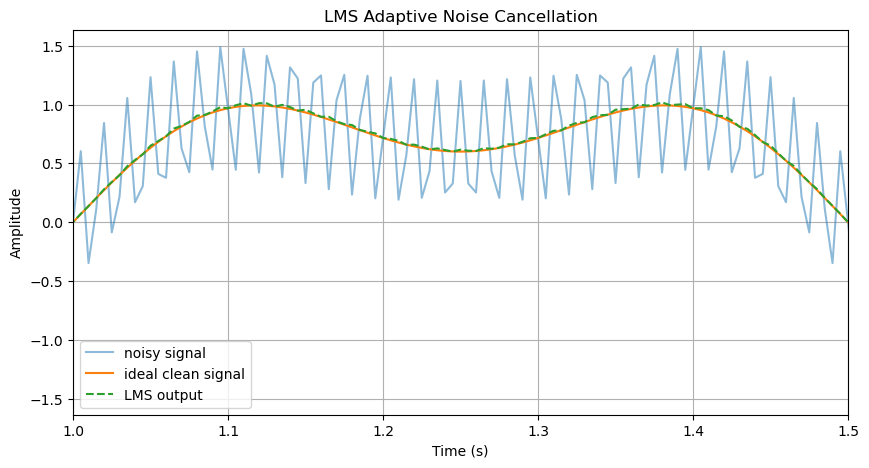

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(t, d, label = "noisy signal", alpha=0.5)
plt.plot(t, clean, label="ideal clean signal")
plt.plot(t, e, label="LMS output", linestyle="--")
plt.xlim(1, 1.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("LMS Adaptive Noise Cancellation")
plt.legend()
plt.grid(True)
plt.show()

#### Important difference from previous FIR/IIR filters:

    Previously, I designed fixed filters to attenuate unwanted frequency ranges. Sometimes, those filters also attenuated useful frequencies or introduced delay.

    Here, the LMS filter uses a separate noise reference to learn the interference and subtract it directly. That's why it can preserve the useful signal so well in this simulation. 

Next, I want to measure RMSe before and after filtering :

In [20]:
#using interval from 1-5 seconds, after the coefficients has converged
mask = (t>= 1)
rmse_before = np.sqrt(np.mean((d[mask] - clean[mask]) ** 2))
rmse_after = np.sqrt(np.mean((e[mask] - clean[mask]) ** 2))
print(f"RMSE before LMS = {rmse_before:.4f}")
print(f"RMSE after LMS  = {rmse_after:.4f}")

RMSE before LMS = 0.4243
RMSE after LMS  = 0.0126


In [21]:
improvement = (rmse_before - rmse_after) / rmse_before * 100
print(f"RMSE reduction = {improvement:.2f}%")

RMSE reduction = 97.03%


Now, I want to examine how changing mu affects the learning speed and the fluctuations of the adaptive coefficients.

I will test mu = [0.005, 0.05, 0.2]

what I expect:

    0.005 -> slow learning and smaller fluctuations
    0.05 -> moderate learning speed
    0.2 -> faster learning, potentially larger fluctuations

mu = 0.005: RMSE = 0.0622
mu = 0.05: RMSE = 0.0126
mu = 0.2: RMSE = 0.0519


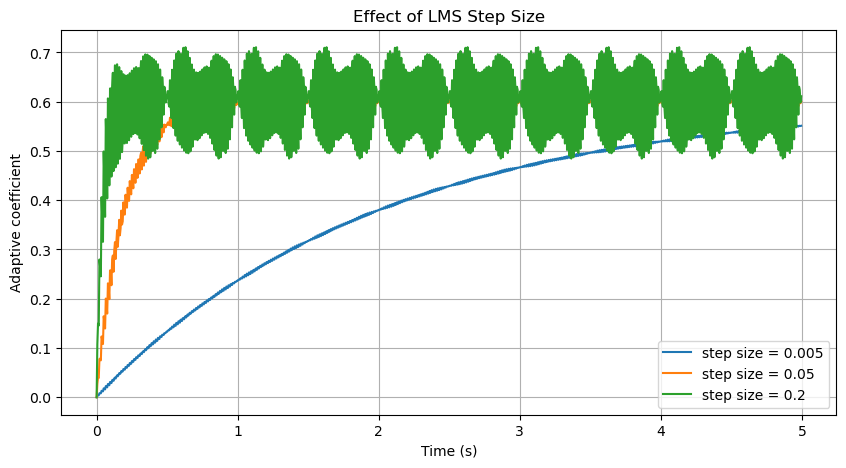

In [24]:
step_sizes = [0.005, 0.05, 0.2]
plt.figure(figsize=(10, 5))

for mu in step_sizes:
    w = 0.0
    y = np.zeros(N)
    e = np.zeros(N)
    w_history = np.zeros(N)

    for n in range(N):
        y[n] = w * x_ref[n]
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * x_ref[n]
        w_history[n] = w

    mask = t >= 3
    rmse = np.sqrt(np.mean((e[mask] - clean[mask]) ** 2))
    print(f"mu = {mu}: RMSE = {rmse:.4f}")

    plt.plot(t, w_history, label = f"step size = {mu}")

plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("Effect of LMS Step Size")
plt.legend()
plt.grid(True)
plt.show()

RMSE demonstartes that a larger step size does not necessarily produce a more accurate adaptive filter!

#### Next situation:

    If the reference and the actual interference have different phases:

In [3]:
# Phase-shifted interference experiment

fs = 200
duration = 5
N = fs * duration
t = np.arange(N) / fs

clean = (np.sin(2*np.pi*1*t) + 0.4*np.sin(2*np.pi*3*t))

# Reference signal
x_ref = np.sin(2*np.pi*65*t)

# Interference with a 45-degree phase shift
noise_phase = 0.6 * np.sin(2*np.pi*65*t + np.pi/4)

# Noisy measurement
d_phase = clean + noise_phase

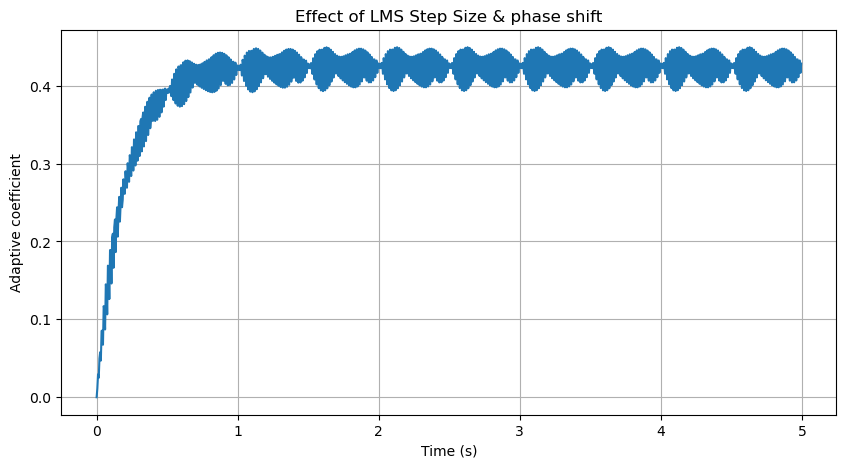

In [8]:
mu = 0.05
w = 0.0
y_phase = np.zeros(N)
e_phase = np.zeros(N)
w_history_phase = np.zeros(N)
for n in range(N):
    y_phase[n] = w * x_ref[n]
    e_phase[n] = d_phase[n] - y_phase[n]
    w = w + mu * e_phase[n] * x_ref[n]
    w_history_phase[n] = w
plt.figure(figsize=(10, 5))
plt.plot(t, w_history_phase)
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("Effect of LMS Step Size & phase shift")
plt.grid(True)
plt.show()

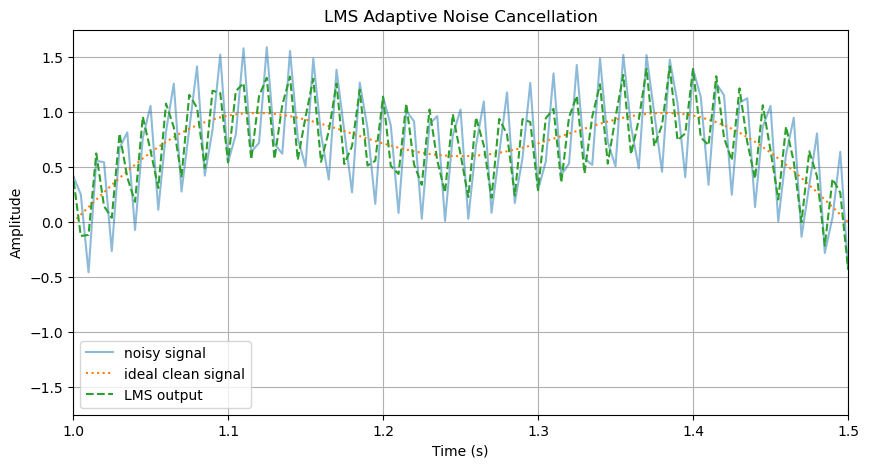

In [13]:
#Noise cancellation
plt.figure(figsize=(10, 5))
plt.plot(t, d_phase, label = "noisy signal", alpha = 0.5)
plt.plot(t, clean, label = "ideal clean signal", linestyle = ":")
plt.plot(t, e_phase, label = "LMS output", linestyle = "--")
plt.xlim(1, 1.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("LMS Adaptive Noise Cancellation")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
#Compare RMSE
mask = t >= 1
rmse_before = np.sqrt(np.mean((d_phase[mask] - clean[mask]) ** 2))
rmse_after = np.sqrt(np.mean((e_phase[mask] - clean[mask]) ** 2))
print(f"RMSE before LMS = {rmse_before:.4f}")
print(f"RMSE after LMS  = {rmse_after:.4f}")

RMSE before LMS = 0.4243
RMSE after LMS  = 0.3022


It is obvious that the algorithm cannot adequately remove the phase-shifted interference with only one fixed coefficient!

    First graph shows coefficients converging near 0.424 instead of 0.6

    Second graph shows substantial interference remaining in the green LMS output, which explains the high RMSE

This is where the multi-tap LMS is used:

I will use two coefficients. The reference will contain current and delayed sample, and because the reference is a sine wave, the delayed sample has a different phase.

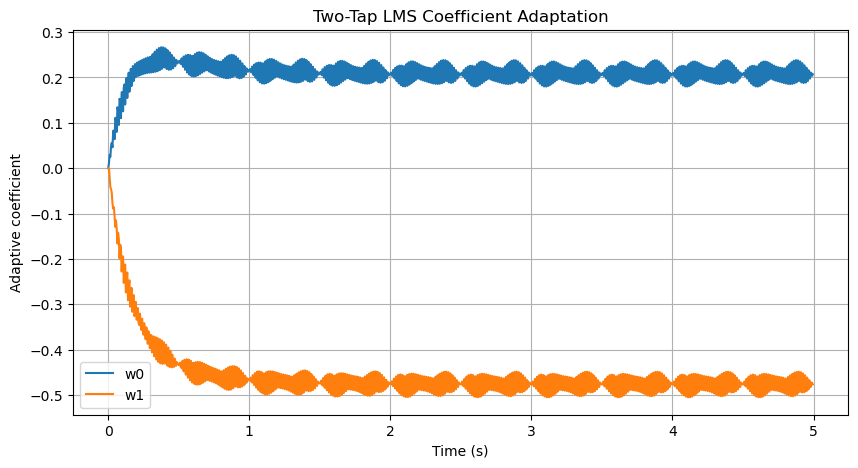

In [14]:
mu = 0.05
w = np.zeros(2)
y_multi = np.zeros(N)
e_multi = np.zeros(N)
w_history_multi = np.zeros((N, 2))
for n in range(1, N):
    x_vector = np.array([x_ref[n], x_ref[n-1]])
    y_multi[n] = np.dot(w, x_vector)
    e_multi[n] = d_phase[n] - y_multi[n]
    w = w + mu * e_multi[n] * x_vector
    w_history_multi[n] = w

plt.figure(figsize=(10, 5))
plt.plot(t, w_history_multi[:, 0], label="w0")
plt.plot(t, w_history_multi[:, 1], label="w1")
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("Two-Tap LMS Coefficient Adaptation")
plt.legend()
plt.grid(True)
plt.show()

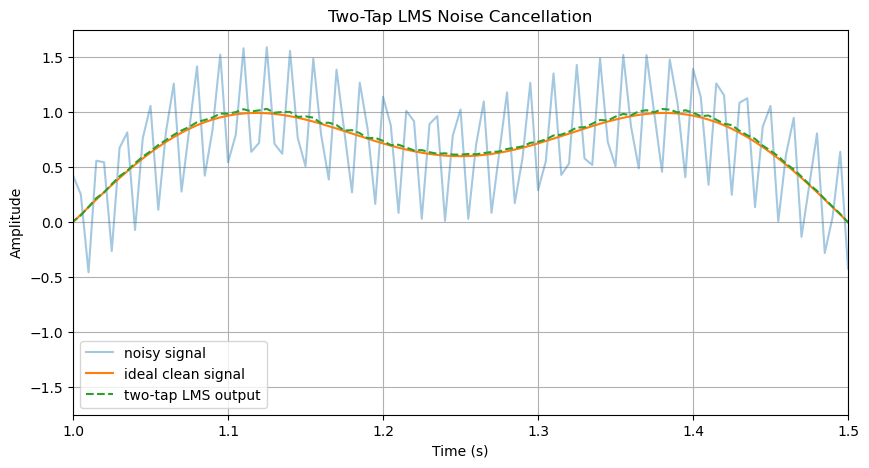

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(t, d_phase, label="noisy signal", alpha=0.4)
plt.plot(t, clean, label="ideal clean signal")
plt.plot(t, e_multi, label="two-tap LMS output", linestyle="--")
plt.xlim(1, 1.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Two-Tap LMS Noise Cancellation")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
mask = t >= 1
rmse_multi = np.sqrt(np.mean((e_multi[mask] - clean[mask]) ** 2))
rmse_one = np.sqrt(np.mean((e_phase[mask] - clean[mask])**2))
print(f"One-tap LMS RMSE = {rmse_one:.4f}")
print(f"Two-tap LMS RMSE = {rmse_multi:.4f}")

One-tap LMS RMSE = 0.3022
Two-tap LMS RMSE = 0.0210


The two-tap LMS produced much lower RMSE because it can model the phase difference between the interference and the reference.

#### Conclusion:

A one-tap LMS filter can estimate interference that is a scaled version of its reference, but a multi-tap LMS filter can model more complicated relationships, including phase differences.